# Demographics & incumbency

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from pathlib import Path

# project root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'clean').is_dir())
CLEAN = ROOT / 'clean' / 'election_results'

panel = pd.read_csv(CLEAN / 'ohio_county_panel.csv')
races = pd.read_csv(CLEAN / 'senate_races.csv')
OUT = ROOT / 'output' / 'dem_incumbent'
OUT.mkdir(parents=True, exist_ok=True)

             2012    2024
OLS slope -0.0034  0.0024


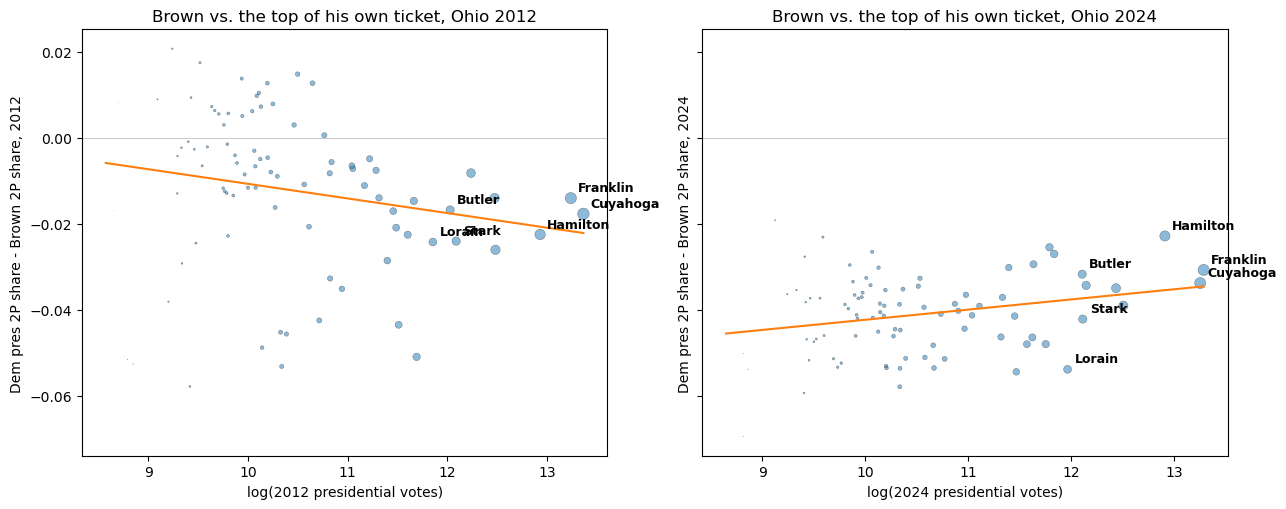

In [2]:
# AI was used to create this graph
# Figure 8: pres share minus Brown share by county size, 2012 and 2024
def gap_plot(yr, ax=None):
    g = panel.assign(gap=panel[f'dem2p_pres_{yr}'] - panel[f'dem2p_sen_{yr}'],
                     logv=np.log(panel[f'votes_pres_{yr}']))
    ols = smf.ols('gap ~ logv', g).fit()
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 5.5))
    ax.scatter(g.logv, g.gap, s=3*(g.logv - g.logv.min())**2,
               alpha=.5, edgecolor='k', linewidth=.3)
    xs = np.linspace(g.logv.min(), g.logv.max(), 100)
    ax.plot(xs, ols.predict({'logv': xs}), 'C1', label='OLS')
    big = ['FRANKLIN','CUYAHOGA','HAMILTON','STARK','BUTLER','LORAIN']
    for _, r in g[g.county_name.str.upper().str.contains('|'.join(big), na=False)].iterrows():
        ax.annotate(r.county_name.title(), (r.logv, r.gap), fontsize=9,
                    fontweight='bold', xytext=(5,5), textcoords='offset points')
    ax.axhline(0, color='#ccc', lw=.8, zorder=0)
    ax.set(xlabel=f'log({yr} presidential votes)',
           ylabel=f'Dem pres 2P share - Brown 2P share, {yr}',
           title=f'Brown vs. the top of his own ticket, Ohio {yr}')
    
    return ols

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
o12 = gap_plot(2012, axes[0])
o24 = gap_plot(2024, axes[1])
fig.tight_layout()
fig.savefig(OUT / 'brown_gap_by_county_size_2012_2024.png', dpi=200)
print(pd.DataFrame({'2012': [o12.params.logv], '2024': [o24.params.logv]},
                   index=['OLS slope']).round(4))

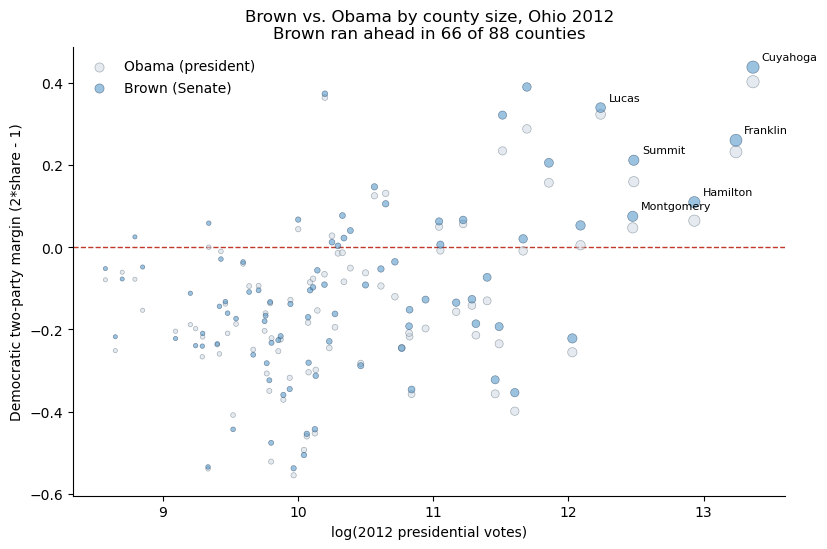

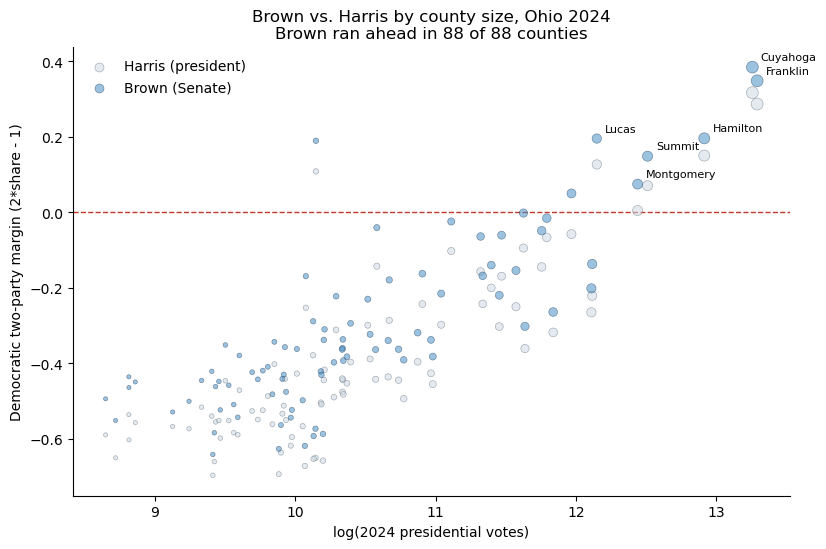

In [3]:
# AI was used to create this graph
# Figure 7: Brown vs. Obama 2012 and Harris 2024 by county size; counties Brown ran ahead
for yr, pres_name in [(2012, 'Obama'), (2024, 'Harris')]:
    g = panel.assign(logv=np.log(panel[f'votes_pres_{yr}']),
                     pres=2 * panel[f'dem2p_pres_{yr}'] - 1,
                     sen=2 * panel[f'dem2p_sen_{yr}'] - 1)
    fig, ax = plt.subplots(figsize=(8.4, 5.6))
    s = 3 * (g.logv - g.logv.min()) ** 2 + 9     # +9 keeps the smallest visible
    ax.scatter(g.logv, g.pres, s=s, alpha=.55, facecolor='#cfd9e2',
               edgecolor='#5b6b7a', linewidth=.45,
               label=f'{pres_name} (president)')
    ax.scatter(g.logv, g.sen, s=s, alpha=.55, facecolor='#4a90c4',
               edgecolor='#1b3a5c', linewidth=.45, label='Brown (Senate)')
    for _, r in g.nlargest(6, f'votes_pres_{yr}').iterrows():
        ax.annotate(r.county_name.title(), (r.logv, r.sen), fontsize=8,
                    xytext=(6, 5), textcoords='offset points')
    ax.axhline(0, color='#c0392b', lw=1, ls='--', zorder=0)
    ahead = int((g.sen > g.pres).sum())
    ax.set(xlabel=f'log({yr} presidential votes)',
           ylabel='Democratic two-party margin (2*share - 1)',
           title=f'Brown vs. {pres_name} by county size, Ohio {yr}\n'
                 f'Brown ran ahead in {ahead} of {len(g)} counties')
    ax.legend(frameon=False)
    ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    fig.savefig(ROOT / 'output' / 'dem_incumbent' / f'brown_vs_{pres_name.lower()}_{yr}.png', dpi=200)
    plt.show()

In [4]:
# 2024 run-ahead: Dem Senate share minus Dem presidential share, every 2024 race (specials too)
pres = pd.read_csv(CLEAN / 'pres_statewide.csv')
pres24 = pres[(pres.year == 2024) & (pres.state_po != 'US')].set_index('state_po').dem2p_pres
s24 = races[races.year == 2024].copy()
s24['label'] = s24.state_po + np.where(s24.special, ' (special)', '')
ra = pd.DataFrame({'sen': s24.dem2p_sen.values, 'pres': s24.state_po.map(pres24).values}, index=s24.label)
ra['runahead'] = ra.sen - ra.pres
ra = ra.sort_values('runahead', ascending=False)
OH_RA = ra.loc['OH', 'runahead']
# Ohio, median, Brown above median (share points)
print(round(OH_RA, 4), round(ra.runahead.median(), 4), round(OH_RA - ra.runahead.median(), 4))

0.0378 0.0115 0.0263


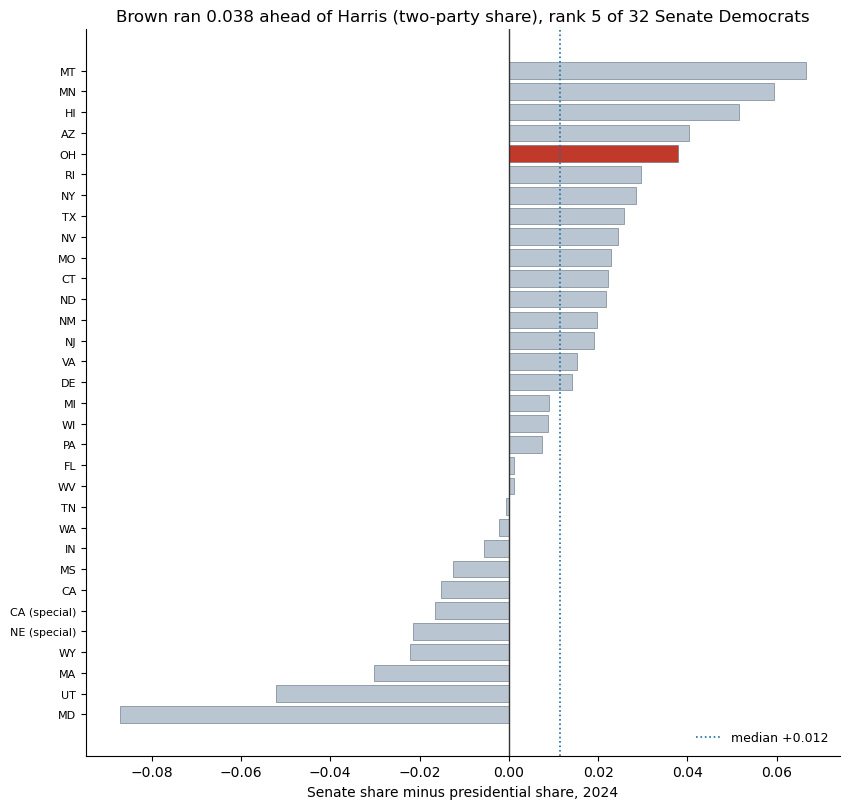

In [5]:
# AI was used to create this graph
# Figure 9
fig, ax = plt.subplots(figsize=(8.6, 8.2))
cols = ['#c0392b' if s == 'OH' else '#b9c6d2' for s in ra.index]
y = np.arange(len(ra))[::-1]
ax.barh(y, ra.runahead, color=cols, edgecolor='#5b6b7a', linewidth=.4)
ax.set_yticks(y)
ax.set_yticklabels(ra.index, fontsize=8)
ax.axvline(0, color='#333', lw=1)
ax.axvline(ra.runahead.median(), color='#1b6ca8', lw=1.2, ls=':',
           label=f'median {ra.runahead.median():+.3f}')
ax.set(xlabel='Senate share minus presidential share, 2024',
       title=f'Brown ran {OH_RA:.3f} ahead of Harris (two-party share), rank '
             f'{list(ra.index).index("OH") + 1} of {len(ra)} Senate Democrats')
ax.legend(frameon=False, fontsize=9, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(ROOT / 'output' / 'dem_incumbent' / 'runahead_2024_by_state.png', dpi=200)
plt.show()

swing 1.388 0.7


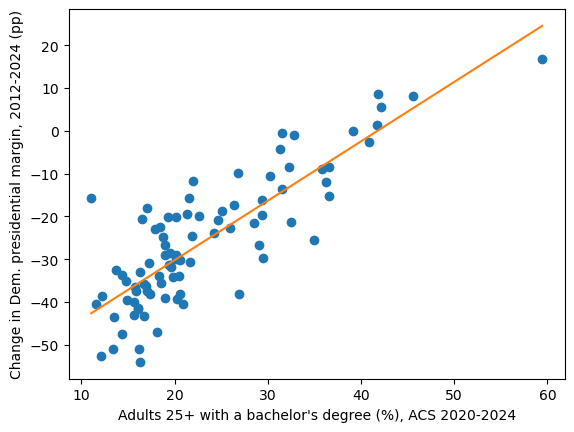

runahead -0.083 0.17


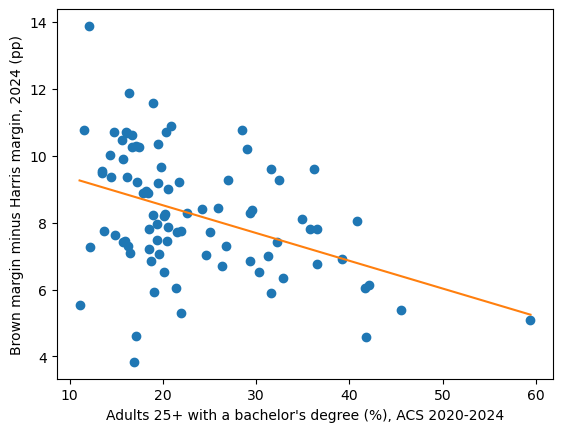

88 of 88 counties


In [6]:
# Figures 5 and 6: county college share (ACS 2020-24) vs. 2012-24 swing and Brown's 2024 run-ahead
edu = pd.read_csv(ROOT / 'clean' / 'demographics' / 'ohio_county_education.csv')
c = panel.merge(edu[['county_fips', 'ba_share_2024']], on='county_fips')
c['ba'] = c.ba_share_2024 * 100
c['swing'] = (c.dem2p_pres_2024 - c.dem2p_pres_2012) * 200          # margin change, pp
c['runahead'] = (c.dem2p_sen_2024 - c.dem2p_pres_2024) * 200        # Brown minus Harris margin, pp

for y, lab, fname in [('swing', 'Change in Dem. presidential margin, 2012-2024 (pp)', 'education_swing.png'),
                      ('runahead', 'Brown margin minus Harris margin, 2024 (pp)', 'education_brown_runahead.png')]:
    fit = smf.ols(f'{y} ~ ba', c).fit()
    print(y, round(fit.params.ba, 3), round(fit.rsquared, 2))
    fig, ax = plt.subplots()
    ax.scatter(c.ba, c[y])
    xs = np.linspace(c.ba.min(), c.ba.max(), 50)
    ax.plot(xs, fit.params.Intercept + fit.params.ba * xs, color='C1')
    ax.set(xlabel="Adults 25+ with a bachelor's degree (%), ACS 2020-2024", ylabel=lab)
    fig.savefig(OUT / fname, dpi=200, bbox_inches='tight')
    plt.show()
print((c.runahead > 0).sum(), 'of', len(c), 'counties')

In [7]:
# Brown appeal adjustment
# premium: Brown's 2024 run-ahead minus the median 2024 Senate Democrat's
# credited: part already in the baseline through S_lag (b4 x premium)
P26 = pd.read_csv(CLEAN / 'baseline_panel.csv').query('year == 2026').iloc[0]
BASE = pd.read_csv(ROOT / 'output' / 'forecast' / 'baseline_forecast.csv').iloc[0]
premium = P26.SL_run * 200                 # margin, pp
credited = BASE.b_S_lag * premium
adjust = premium - credited
print(round(premium, 2), round(credited, 2), round(adjust, 2), round(BASE.margin_pp + adjust, 2))
pd.DataFrame([{'premium_pp': premium, 'credited_pp': credited, 'adjust_pp': adjust}]).to_csv(
    ROOT / 'output' / 'forecast' / 'brown_adjustment.csv', index=False)

5.26 0.76 4.5 5.65


In [8]:
# Brown's statewide run-ahead of the top of the ticket (share points)
oh_pres = pres[pres.state_po == 'OH'].set_index('year').dem2p_pres
oh_sen = races[races.state_po == 'OH'].set_index('year').dem2p_sen
pd.Series({y: (oh_sen[y] - oh_pres[p]) * 100 for y, p in [(2006, 2004), (2012, 2012), (2018, 2016), (2024, 2024)]}).round(1)

2006    7.2
2012    1.6
2018    7.7
2024    3.8
dtype: float64